# Check of the colour conversion (g-i) = -0.56 + 1.34 (BP-RP) (Nada, 2026-11-01)

The DCR reference colour of each CCD-exposure is (g-i)_ref = -0.56 + 1.34 x ccdbprp, where ccdbprp is the median Gaia
BP-RP of the Community Pipeline's astrometric calibration stars on that CCD (survey-ccds). Dustin: the relation is an
empirical fit to stars. Two checks:
1. star by star: observed g-i (Tractor fluxes) vs observed Gaia BP-RP (no extinction correction on either, as in the
   pipeline) for clean, unsaturated Gaia stars with G 16-20 and S/N > 50 in g and i, in 8 slices; own fit and residuals
   from the adopted relation vs BP-RP, G and E(B-V);
2. as used: per CCD-exposure, the median g-i of our Gaia stars on that CCD vs -0.56 + 1.34 ccdbprp.
Internal figure run/plots/colour_conversion_check.pdf.

In [1]:
import os, sys
import numpy as np
import fitsio
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, plot_style as ps
from py_files.pm_analysis import COMBINED_DIR
ps.apply()
SLICES = ['000', '008', '016', '024', '032', '040', '048', '056']
A, B = -0.56, 1.34
MASK = (1 << 1) | (1 << 11) | (1 << 2) | (1 << 3) | (1 << 4) | (1 << 14)
cols = ['brickid', 'objid', 'flux_g', 'flux_i', 'flux_ivar_g', 'flux_ivar_i', 'gaia_phot_g_mean_mag', 'gaia_phot_bp_mean_mag',
        'gaia_phot_rp_mean_mag', 'maskbits', 'ebv'] if 'ebv' in fitsio.FITS(os.path.join(COMBINED_DIR, 'gaia-objects-000.fits'))[1].get_colnames() else \
       ['brickid', 'objid', 'flux_g', 'flux_i', 'flux_ivar_g', 'flux_ivar_i', 'gaia_phot_g_mean_mag', 'gaia_phot_bp_mean_mag',
        'gaia_phot_rp_mean_mag', 'maskbits', 'mw_transmission_g']
T = np.concatenate([fitsio.read(os.path.join(COMBINED_DIR, f'gaia-objects-{d}.fits'), columns=cols) for d in SLICES])
with np.errstate(all='ignore'):
    gi = -2.5 * np.log10(T['flux_g'] / T['flux_i'])
    snr = np.minimum(T['flux_g'] * np.sqrt(T['flux_ivar_g']), T['flux_i'] * np.sqrt(T['flux_ivar_i']))
    bprp = T['gaia_phot_bp_mean_mag'] - T['gaia_phot_rp_mean_mag']
    ebv = T['ebv'] if 'ebv' in T.dtype.names else -np.log10(T['mw_transmission_g']) * 2.5 / 3.214   # g: A_g = 3.214 E(B-V)
G = T['gaia_phot_g_mean_mag']
sel = (np.isfinite(gi) & (snr > 50) & (G > 16) & (G < 20) & (T['gaia_phot_bp_mean_mag'] > 0) & (T['gaia_phot_rp_mean_mag'] > 0)
       & ((T['maskbits'].astype(np.int64) & MASK) == 0))
print(f'{sel.sum():,} Gaia stars')

937,253 Gaia stars


In [2]:
# 1. star by star
x, y = bprp[sel], gi[sel]
fit = (x > 0.3) & (x < 2.5)
keep = fit.copy()
for _ in range(5):   # iterative 3-sigma clipping
    c = np.polyfit(x[keep], y[keep], 1)
    r = y - np.polyval(c, x)
    s = 1.4826 * np.median(np.abs(r[keep]))
    keep = fit & (np.abs(r) < 3 * s)
print(f'own fit (0.3 < BP-RP < 2.5, clipped): g-i = {c[1]:+.3f} + {c[0]:.3f} (BP-RP); robust scatter {s:.3f} mag; adopted -0.56 + 1.34')
res = y - (A + B * x)
edges = np.arange(0.2, 3.41, 0.2)
print('residual from the adopted relation (median, mag) by BP-RP bin [fraction of stars]:')
xc, med, err = [], [], []
for a, b in zip(edges[:-1], edges[1:]):
    m = (x >= a) & (x < b)
    if m.sum() > 200:
        xc.append(np.median(x[m])); med.append(np.median(res[m])); err.append(1.2533 * 1.4826 * np.median(np.abs(res[m] - np.median(res[m]))) / np.sqrt(m.sum()))
        print(f'  {a:.1f}-{b:.1f}: {med[-1]:+.3f}  [{m.mean():.1%}]')
for name, v, e in [('G', G[sel], [16, 17, 18, 19, 20]), ('E(B-V)', ebv[sel], [0, 0.02, 0.04, 0.08, 0.2])]:
    print(f'median residual (0.3 < BP-RP < 2.5) by {name}: ' + ', '.join(f'{a}-{b}: {np.median(res[fit & (v >= a) & (v < b)]):+.3f}'
          for a, b in zip(e[:-1], e[1:]) if (fit & (v >= a) & (v < b)).sum() > 200))

own fit (0.3 < BP-RP < 2.5, clipped): g-i = -0.555 + 1.338 (BP-RP); robust scatter 0.060 mag; adopted -0.56 + 1.34
residual from the adopted relation (median, mag) by BP-RP bin [fraction of stars]:
  0.2-0.4: +0.031  [0.5%]
  0.4-0.6: +0.088  [1.5%]
  0.6-0.8: +0.013  [9.3%]
  0.8-1.0: -0.008  [14.9%]
  1.0-1.2: -0.023  [13.7%]
  1.2-1.4: -0.004  [8.3%]
  1.4-1.6: +0.035  [6.6%]
  1.6-1.8: +0.065  [6.5%]
  1.8-2.0: +0.061  [7.0%]
  2.0-2.2: +0.027  [7.2%]
  2.2-2.4: -0.029  [7.6%]
  2.4-2.6: -0.107  [6.9%]
  2.6-2.8: -0.199  [4.4%]
  2.8-3.0: -0.286  [1.8%]
  3.0-3.2: -0.358  [0.6%]
  3.2-3.4: -0.435  [0.2%]
median residual (0.3 < BP-RP < 2.5) by G: 16-17: -0.003, 17-18: -0.001, 18-19: -0.004, 19-20: +0.027
median residual (0.3 < BP-RP < 2.5) by E(B-V): 0-0.02: +0.007, 0.02-0.04: +0.003, 0.04-0.08: -0.003, 0.08-0.2: +0.003


In [3]:
# 2. as used: per CCD-exposure median g-i of our Gaia stars vs the reference colour from ccdbprp
keys, giref, ccd_index = dcr_fit.ccd_reference_colour()
tk = np.sort((T['brickid'][sel].astype(np.int64) << 32) | T['objid'][sel].astype(np.int64))
gi_by_key = dict(zip(((T['brickid'][sel].astype(np.int64) << 32) | T['objid'][sel].astype(np.int64)).tolist(), gi[sel].tolist()))
rows = []
for d in SLICES[:4]:
    E = fitsio.read(os.path.join(COMBINED_DIR, f'gaia-epochs-{d}.fits'), columns=['brickid', 'objid', 'expnum', 'ccdname'])
    ek = (E['brickid'].astype(np.int64) << 32) | E['objid'].astype(np.int64)
    p = np.clip(np.searchsorted(tk, ek), 0, len(tk) - 1); ok = tk[p] == ek
    E, ek = E[ok], ek[ok]
    names = np.char.strip(E['ccdname'].astype(str)); un = np.unique(names)
    cidx = np.array([ccd_index.get(n, -1) for n in un])[np.searchsorted(un, names)]
    k = dcr_fit._key(E['expnum'], cidx)
    rows.append((k, np.array([gi_by_key[v] for v in ek.tolist()])))
k = np.concatenate([r[0] for r in rows]); g_ = np.concatenate([r[1] for r in rows])
o = np.argsort(k); k, g_ = k[o], g_[o]
starts = np.flatnonzero(np.r_[True, k[1:] != k[:-1]]); n = np.diff(np.r_[starts, len(k)])
medgi = np.array([np.median(g_[a:a + m]) for a, m in zip(starts, n)])
uk = k[starts]
p = np.clip(np.searchsorted(keys, uk), 0, len(keys) - 1); hit = keys[p] == uk
ok = hit & (n >= 10)
d_ = medgi[ok] - giref[p][ok]
print(f'{ok.sum():,} CCD-exposures with >= 10 of our clean Gaia stars: median g-i of our stars minus the reference colour: '
      f'median {np.median(d_):+.3f} mag, robust scatter {1.4826 * np.median(np.abs(d_ - np.median(d_))):.3f} mag')
print('note: our stars are not the CP calibrators (fainter, different selection), so the scatter includes the difference of the two star samples')

235,109 CCD-exposures with >= 10 of our clean Gaia stars: median g-i of our stars minus the reference colour: median +0.206 mag, robust scatter 0.280 mag
note: our stars are not the CP calibrators (fainter, different selection), so the scatter includes the difference of the two star samples


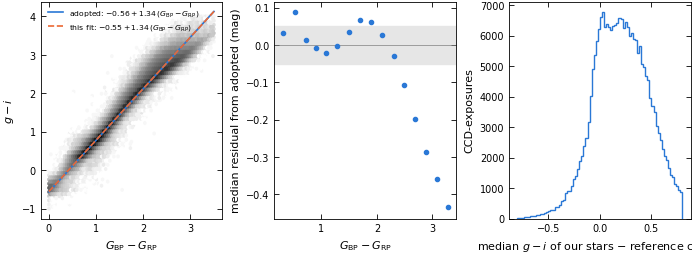

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(ps.PAGE, 2.6), layout='constrained')
ax[0].hexbin(x, y, gridsize=80, extent=(0, 3.5, -1, 4), bins='log', cmap=ps.DENSITY, mincnt=1)
xx = np.linspace(0, 3.5, 10)
ax[0].plot(xx, A + B * xx, color=ps.SERIES[0], label='adopted: $-0.56 + 1.34\\,(G_{\\rm BP}-G_{\\rm RP})$')
ax[0].plot(xx, np.polyval(c, xx), color=ps.SERIES[1], ls='--', label=f'this fit: ${c[1]:+.2f} + {c[0]:.2f}\\,(G_{{\\rm BP}}-G_{{\\rm RP}})$')
ax[0].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); ax[0].set_ylabel('$g-i$'); ax[0].legend(fontsize=5.5)
ax[1].errorbar(xc, med, err, fmt='o', ms=3, color=ps.SERIES[0]); ax[1].axhline(0, color='0.5', lw=0.5)
ax[1].axhspan(-0.05, 0.05, color='0.9', zorder=0)
ax[1].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); ax[1].set_ylabel('median residual from adopted (mag)')
ax[2].hist(d_, bins=np.linspace(-0.8, 0.8, 81), histtype='step', color=ps.SERIES[0])
ax[2].set_xlabel('median $g-i$ of our stars $-$ reference colour'); ax[2].set_ylabel('CCD-exposures')
plt.savefig('plots/colour_conversion_check.pdf')